In [1]:

import pandas as pd
import matplotlib.pyplot as plt

print("Análisis tributario de Guatemala")
print("Versión de Pandas:", pd.__version__)


Análisis tributario de Guatemala
Versión de Pandas: 2.3.3


In [2]:
%pip install openpyxl

You should consider upgrading via the '/Users/diegoxoyonlorenzana/MisProyectos/jupyter-env/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd

df = pd.read_excel(
    "TR2026.xlsx",
    sheet_name="Recaudación 2026 Depto. y AE",
    header=3,
    usecols="B:X",
    dtype={"Código Actividad": str}
)

display(df.head(10))
print("Dimensiones:", df.shape)


,Mes,Código Actividad,Nombre Actividad,Nombre Sección,Departamento,IVA Importación,DAI,ISR,ISO,IEMA,...,IVA Doméstico,BEBIDAS,TABACO,PETROLEO,CEMENTO,TIMBRES,VEHÍCULOS,IPRIMA,OTROS,TOTAL
0,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Chiquimula,96913.76,6310.25,798.33,0.0,0.0,...,88690.93,0.0,0.0,0.0,0.0,1740.00,185265.27,78970.85,0.0,458689.39
1,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Sacatepéquez,30793.11,5564.33,1303.84,0.0,0.0,...,115095.26,0.0,0.0,0.0,0.0,3175.39,236153.07,27917.02,0.0,427300.86
2,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Baja Verapaz,7413.09,1149.51,308.28,0.0,0.0,...,42711.48,0.0,0.0,0.0,0.0,1590.00,64486.78,2544.80,0.0,120203.94
3,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Zacapa,24062.97,2383.62,100.07,0.0,0.0,...,45644.61,0.0,0.0,0.0,0.0,1085.00,106695.82,3793.88,0.0,184874.59
4,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Jutiapa,128666.27,7983.93,244.36,0.0,0.0,...,141668.85,0.0,0.0,0.0,0.0,4239.55,243889.41,121752.11,0.0,648444.48
5,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Santa Rosa,61449.49,5470.25,949.03,0.0,0.0,...,92660.59,0.0,0.0,0.0,0.0,2125.00,167819.50,63040.98,0.0,393514.84
6,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Chimaltenango,120753.48,6283.19,5394.03,0.0,0.0,...,221091.38,0.0,0.0,0.0,0.0,12484.48,272215.82,98947.39,0.0,737169.77
7,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Quiché,70313.25,5555.13,391.15,0.0,0.0,...,154340.22,0.0,0.0,0.0,0.0,3439.00,271743.66,39586.20,0.0,545368.61
8,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Huehuetenango,158620.28,6058.40,7809.63,0.0,0.0,...,239508.29,0.0,0.0,0.0,0.0,3863.04,395799.94,119228.05,0.0,930887.63
9,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,San Marcos,323516.29,20234.78,1061.01,0.0,0.0,...,223824.92,0.0,0.0,0.0,0.0,7267.00,495382.85,315285.11,0.0,1386571.96


Dimensiones: (69388, 23)


In [3]:

# Ver columnas y tipos de datos
print(df.info())

# Revisar registros faltantes
print(df.isnull().sum())

# Meses disponibles
print("Meses:", sorted(df["Mes"].dropna().unique()))

# Departamentos disponibles
print("Departamentos:", df["Departamento"].nunique())




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69388 entries, 0 to 69387
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Mes               69388 non-null  int64  
 1   Código Actividad  69388 non-null  object 
 2   Nombre Actividad  69388 non-null  object 
 3   Nombre Sección    69388 non-null  object 
 4   Departamento      69388 non-null  object 
 5   IVA Importación   69388 non-null  float64
 6   DAI               69388 non-null  float64
 7   ISR               69388 non-null  float64
 8   ISO               69388 non-null  float64
 9   IEMA              69388 non-null  float64
 10  IETAAP            69388 non-null  float64
 11  ISET              69388 non-null  int64  
 12  PATRIMONIO        69388 non-null  float64
 13  IVA Doméstico     69388 non-null  float64
 14  BEBIDAS           69388 non-null  float64
 15  TABACO            69388 non-null  float64
 16  PETROLEO          69388 non-null  float6

# Preparación del DataFrame 

Despues de extraer la información del archivo TR2026.xlsx y se procede a realizar la preparación del DataFrame para trabajar sobre una copia y asi conservar los datos originales.

In [4]:
# ---Preparacion del Data Frame
# Crear copia de los datos originales
df_limpio = df.copy()

# Estandarizar nombres de columnas
df_limpio.columns = df_limpio.columns.str.strip()

# Columnas de identificación
categoricas = [
    "Código Actividad",
    "Nombre Actividad",
    "Nombre Sección",
    "Departamento"
]

# Limpiar espacios adicionales
for columna in categoricas:
    df_limpio[columna] = (
        df_limpio[columna]
        .astype("string")
        .str.strip()
    )

# Convertir el mes a número entero
df_limpio["Mes"] = pd.to_numeric(
    df_limpio["Mes"], errors="coerce"
).astype("Int64")

# Identificar columnas de impuestos
impuestos = [
    c for c in df_limpio.columns
    if c not in categoricas + ["Mes", "TOTAL"]
]

# Convertir impuestos y TOTAL a valores numéricos
for columna in impuestos + ["TOTAL"]:
    df_limpio[columna] = pd.to_numeric(
        df_limpio[columna],
        errors="coerce"
    )

display(df_limpio.head())


,Mes,Código Actividad,Nombre Actividad,Nombre Sección,Departamento,IVA Importación,DAI,ISR,ISO,IEMA,...,IVA Doméstico,BEBIDAS,TABACO,PETROLEO,CEMENTO,TIMBRES,VEHÍCULOS,IPRIMA,OTROS,TOTAL
0,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Chiquimula,96913.76,6310.25,798.33,0.0,0.0,...,88690.93,0.0,0.0,0.0,0.0,1740.00,185265.27,78970.85,0.0,458689.39
1,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Sacatepéquez,30793.11,5564.33,1303.84,0.0,0.0,...,115095.26,0.0,0.0,0.0,0.0,3175.39,236153.07,27917.02,0.0,427300.86
2,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Baja Verapaz,7413.09,1149.51,308.28,0.0,0.0,...,42711.48,0.0,0.0,0.0,0.0,1590.00,64486.78,2544.80,0.0,120203.94
3,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Zacapa,24062.97,2383.62,100.07,0.0,0.0,...,45644.61,0.0,0.0,0.0,0.0,1085.00,106695.82,3793.88,0.0,184874.59
4,1,0001.40,Estudiante,Actividades de los hogares como empleadores; a...,Jutiapa,128666.27,7983.93,244.36,0.0,0.0,...,141668.85,0.0,0.0,0.0,0.0,4239.55,243889.41,121752.11,0.0,648444.48


In [5]:

# 1. Valores faltantes
print("VALORES FALTANTES")
display(df_limpio.isnull().sum().to_frame("Faltantes"))

# 2. Registros duplicados por su clave
duplicados = df_limpio.duplicated(
    subset=["Mes", "Código Actividad", "Departamento"]
).sum()

print("Duplicados:", duplicados)

# 3. Valores negativos
negativos = (df_limpio[impuestos + ["TOTAL"]] < 0).sum()

print("VALORES NEGATIVOS")
display(negativos.to_frame("Cantidad"))

# 4. Impuestos sin recaudación
print("TOTAL POR TIPO DE IMPUESTO")
display(df_limpio[impuestos].sum().sort_values())


VALORES FALTANTES


,Faltantes
Mes,0
Código Actividad,0
Nombre Actividad,0
Nombre Sección,0
Departamento,0
IVA Importación,0
DAI,0
ISR,0
ISO,0
IEMA,0


Duplicados: 0
VALORES NEGATIVOS


,Cantidad
IVA Importación,0
DAI,0
ISR,0
ISO,0
IEMA,0
IETAAP,0
ISET,0
PATRIMONIO,0
IVA Doméstico,0
BEBIDAS,0


TOTAL POR TIPO DE IMPUESTO


ISET               0.000000e+00
IEMA               7.117655e+05
IETAAP             1.648587e+06
OTROS              6.700667e+06
PATRIMONIO         1.288250e+07
CEMENTO            1.844796e+08
TABACO             2.437900e+08
TIMBRES            4.988285e+08
BEBIDAS            9.989351e+08
IPRIMA             1.309363e+09
VEHÍCULOS          1.340357e+09
PETROLEO           3.342634e+09
DAI                3.523252e+09
ISO                6.728819e+09
IVA Doméstico      2.102399e+10
IVA Importación    2.125409e+10
ISR                2.470664e+10
dtype: float64

# Validacion de los totales
Se comprueba que el campo TOTAL coincida con la suma de los distintos impuestos de cada registro.

In [6]:

# Sumar los impuestos por registro
df_limpio["TOTAL_CALCULADO"] = (
    df_limpio[impuestos].sum(axis=1)
)

# Calcular diferencia
df_limpio["DIFERENCIA"] = (
    df_limpio["TOTAL"]
    - df_limpio["TOTAL_CALCULADO"]
)

# Identificar diferencias relevantes
inconsistencias = df_limpio[
    df_limpio["DIFERENCIA"].abs() > 0.05
]

print("Registros inconsistentes:", len(inconsistencias))
display(inconsistencias.head(10))


Registros inconsistentes: 1


,Mes,Código Actividad,Nombre Actividad,Nombre Sección,Departamento,IVA Importación,DAI,ISR,ISO,IEMA,...,TABACO,PETROLEO,CEMENTO,TIMBRES,VEHÍCULOS,IPRIMA,OTROS,TOTAL,TOTAL_CALCULADO,DIFERENCIA
61716,8,0162.40,Actividades de apoyo a la ganadería,"Agricultura, ganadería, silvicultura y pesca",Guatemala,2018210.37,237996.75,352601.5,5874.59,0.0,...,0.0,0.0,0.0,1497.07,15171.36,0.0,0.0,3331094.71,3330895.02,199.69


# Analisis de la recaudación por departamento

In [7]:

por_departamento = (
    df_limpio.groupby("Departamento")["TOTAL"]
    .sum()
    .sort_values(ascending=False)
)

participacion = (
    por_departamento / por_departamento.sum() * 100
)

resumen_departamento = pd.DataFrame({
    "Recaudacion_Q": por_departamento,
    "Porcentaje": participacion
})

display(resumen_departamento.round(2))


,Recaudacion_Q,Porcentaje
Departamento,,
Guatemala,7.696484e+10,90.36
Escuintla,1.278882e+09,1.50
Quetzaltenango,1.090834e+09,1.28
Sacatepéquez,6.912980e+08,0.81
Zacapa,5.140040e+08,0.60
Chimaltenango,5.017439e+08,0.59
Huehuetenango,4.540756e+08,0.53
Izabal,3.733049e+08,0.44
Chiquimula,3.437209e+08,0.40


# Sección de Gráficas
A continuación se muestran las gráficas obtenidas a partir de la información preparada anteriormente.

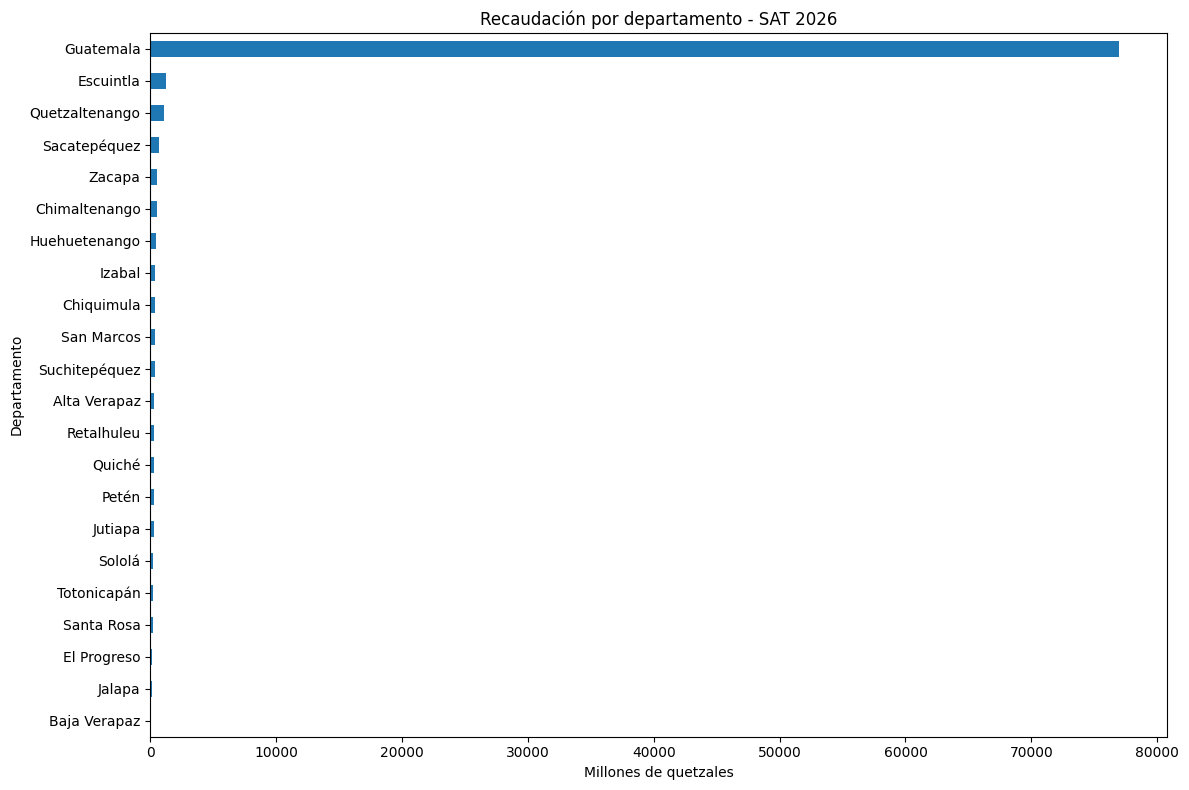

In [8]:

import matplotlib.pyplot as plt

datos_grafica = (
    por_departamento.sort_values() / 1_000_000
)

plt.figure(figsize=(12, 8))
datos_grafica.plot(kind="barh")

plt.title("Recaudación por departamento - SAT 2026")
plt.xlabel("Millones de quetzales")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()


In [9]:
por_departamento_Iva = (
    df_limpio.groupby("Departamento")["IVA Doméstico"]
    .sum()
    .sort_values(ascending=False)
)

participacion = (
    por_departamento_Iva / por_departamento_Iva.sum() * 100
)
display(por_departamento_Iva)


resumen_Iva = pd.DataFrame({
    "Recaudacion_Q": por_departamento_Iva,
    "Porcentaje": participacion
})

display(resumen_Iva.round(2))

Departamento
Guatemala         1.859670e+10
Escuintla         3.898401e+08
Quetzaltenango    2.887221e+08
Sacatepéquez      2.222381e+08
Chimaltenango     1.429317e+08
Izabal            1.420576e+08
Huehuetenango     1.248648e+08
Suchitepéquez     1.233531e+08
Zacapa            1.102343e+08
Alta Verapaz      1.070732e+08
Retalhuleu        9.843164e+07
Chiquimula        9.249921e+07
Petén             9.065375e+07
San Marcos        8.802760e+07
Quiché            8.556336e+07
Jutiapa           7.523560e+07
Sololá            5.820728e+07
Santa Rosa        5.000144e+07
El Progreso       3.990783e+07
Jalapa            3.830250e+07
Totonicapán       3.336004e+07
Baja Verapaz      2.579169e+07
Name: IVA Doméstico, dtype: float64

,Recaudacion_Q,Porcentaje
Departamento,,
Guatemala,1.859670e+10,88.45
Escuintla,3.898401e+08,1.85
Quetzaltenango,2.887221e+08,1.37
Sacatepéquez,2.222381e+08,1.06
Chimaltenango,1.429317e+08,0.68
Izabal,1.420576e+08,0.68
Huehuetenango,1.248648e+08,0.59
Suchitepéquez,1.233531e+08,0.59
Zacapa,1.102343e+08,0.52


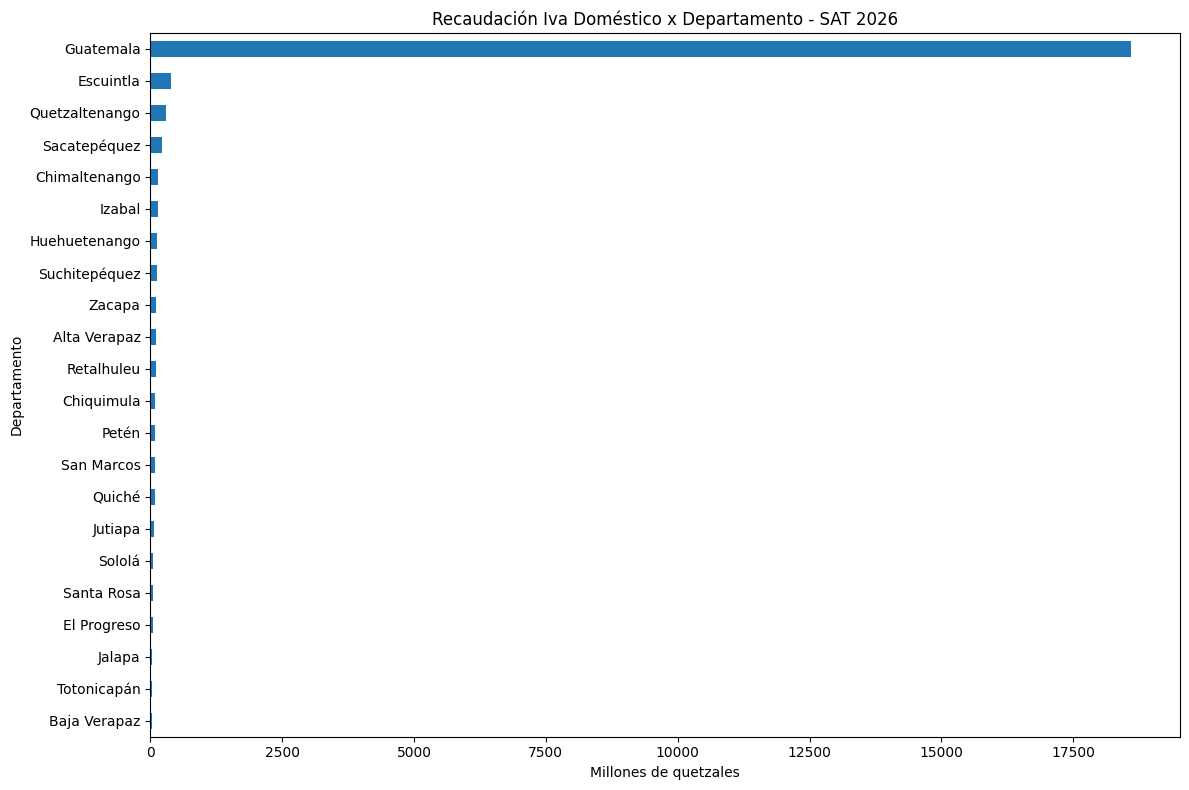

In [13]:
import matplotlib.pyplot as plt

datos_grafica = (
    por_departamento_Iva.sort_values() / 1_000_000
)

plt.figure(figsize=(12, 8))
datos_grafica.plot(kind="barh")

plt.title("Recaudación Iva Doméstico x Departamento - SAT 2026")
plt.xlabel("Millones de quetzales")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

In [10]:
por_departamento_vehiculos = (
    df_limpio.groupby("Departamento")["VEHÍCULOS"]
    .sum()
    .sort_values(ascending=False)
)

participacion = (
    por_departamento_vehiculos / por_departamento_vehiculos.sum() * 100
)
display(por_departamento_Iva)


resumen_Iva = pd.DataFrame({
    "Recaudacion_Q": por_departamento_vehiculos,
    "Porcentaje": participacion
})

display(resumen_Iva.round(2))

Departamento
Guatemala         1.859670e+10
Escuintla         3.898401e+08
Quetzaltenango    2.887221e+08
Sacatepéquez      2.222381e+08
Chimaltenango     1.429317e+08
Izabal            1.420576e+08
Huehuetenango     1.248648e+08
Suchitepéquez     1.233531e+08
Zacapa            1.102343e+08
Alta Verapaz      1.070732e+08
Retalhuleu        9.843164e+07
Chiquimula        9.249921e+07
Petén             9.065375e+07
San Marcos        8.802760e+07
Quiché            8.556336e+07
Jutiapa           7.523560e+07
Sololá            5.820728e+07
Santa Rosa        5.000144e+07
El Progreso       3.990783e+07
Jalapa            3.830250e+07
Totonicapán       3.336004e+07
Baja Verapaz      2.579169e+07
Name: IVA Doméstico, dtype: float64

,Recaudacion_Q,Porcentaje
Departamento,,
Guatemala,5.852567e+08,43.66
Quetzaltenango,7.871927e+07,5.87
Huehuetenango,6.876533e+07,5.13
Escuintla,5.933832e+07,4.43
San Marcos,5.674956e+07,4.23
Chimaltenango,4.502672e+07,3.36
Quiché,4.216238e+07,3.15
Petén,4.141898e+07,3.09
Jutiapa,3.593615e+07,2.68


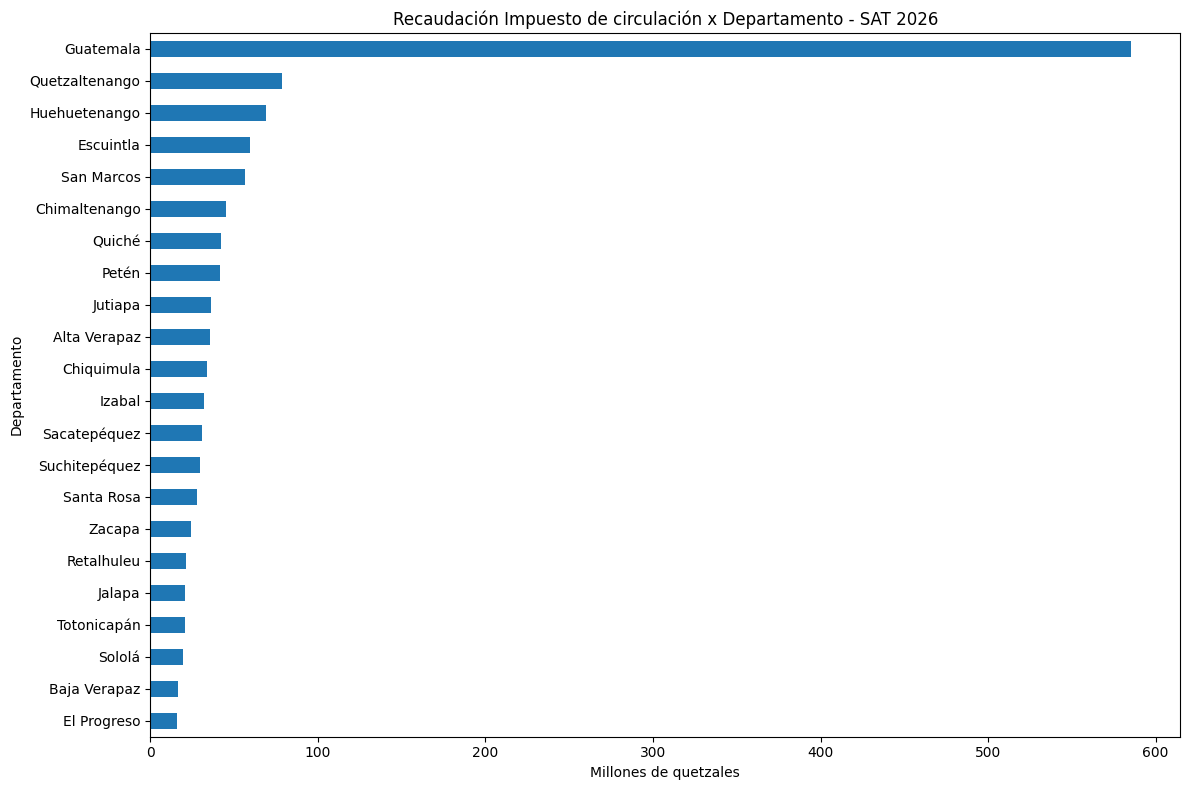

In [11]:
import matplotlib.pyplot as plt

datos_grafica = (
    por_departamento_vehiculos.sort_values() / 1_000_000
)

plt.figure(figsize=(12, 8))
datos_grafica.plot(kind="barh")

plt.title("Recaudación Impuesto de circulación x Departamento - SAT 2026")
plt.xlabel("Millones de quetzales")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

In [16]:
por_total_seccion = (
    df_limpio.groupby("Nombre Sección")["TOTAL"]
    .sum()
    .sort_values(ascending=False)
)

participacion = (
    por_total_seccion / por_total_seccion.sum() * 100
)
display(por_total_seccion)


resumen_seccion = pd.DataFrame({
    "Recaudacion_Q": por_total_seccion,
    "Porcentaje": participacion
})

display(resumen_seccion.round(2))

Nombre Sección
Comercio al por mayor y al por menor; reparación de vehículos automotores y motocicletas                                                           3.449838e+10
Industrias manufactureras                                                                                                                          1.522764e+10
Actividades financieras y de seguros                                                                                                               7.680143e+09
Actividades de servicios administrativos y de apoyo                                                                                                4.374654e+09
Información y comunicaciones                                                                                                                       3.592627e+09
Transporte y almacenamiento                                                                                                                        3.490822e+09
Actividades profesionales

,Recaudacion_Q,Porcentaje
Nombre Sección,,
Comercio al por mayor y al por menor; reparación de vehículos automotores y motocicletas,3.449838e+10,40.50
Industrias manufactureras,1.522764e+10,17.88
Actividades financieras y de seguros,7.680143e+09,9.02
Actividades de servicios administrativos y de apoyo,4.374654e+09,5.14
Información y comunicaciones,3.592627e+09,4.22
Transporte y almacenamiento,3.490822e+09,4.10
"Actividades profesionales, científicas y técnicas",2.690828e+09,3.16
Actividades inmobiliarias,2.580763e+09,3.03
"Suministro de electricidad, gas, vapor y aire acondicionado",2.386159e+09,2.80


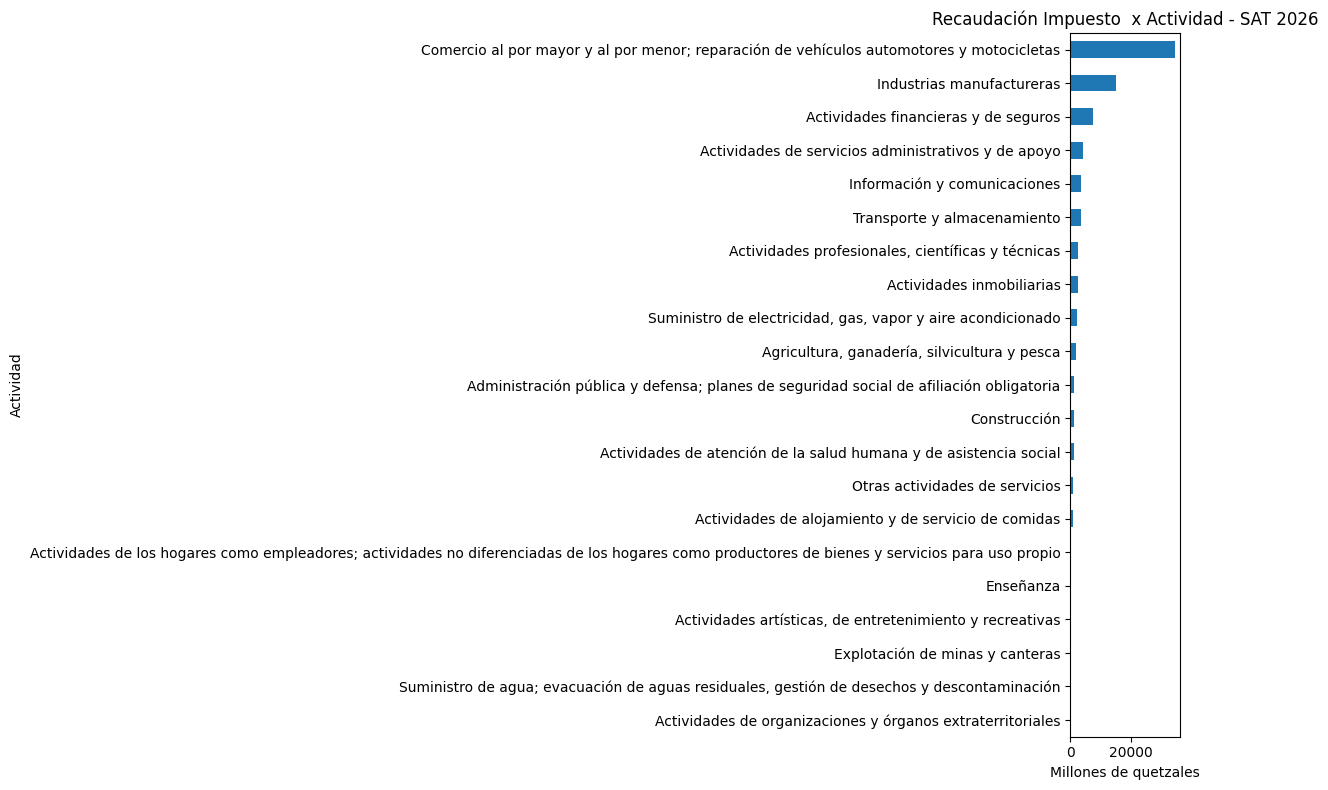

In [17]:
import matplotlib.pyplot as plt

datos_grafica = (
    por_total_seccion.sort_values() / 1_000_000
)

plt.figure(figsize=(12, 8))
datos_grafica.plot(kind="barh")

plt.title("Recaudación Impuesto  x Actividad - SAT 2026")
plt.xlabel("Millones de quetzales")
plt.ylabel("Actividad")
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

df2 = pd.read_excel(
    "sat-recaudacion-departamental.xlsx",
    sheet_name="Datos",
    header=0,
    usecols="A:F",
)

display(df2.head(10))
print("Dimensiones:", df2.shape)

,CodigoDepartamental,Departamento,Anio,Mes,NombreMes,MillonesQ
0,1,Guatemala,2004,1,Ene,2083.406125
1,1,Guatemala,2004,2,Feb,1271.299141
2,1,Guatemala,2004,3,Mar,1376.976356
3,1,Guatemala,2004,4,Abr,1814.669100
4,1,Guatemala,2004,5,May,1801.378395
5,1,Guatemala,2004,6,Jun,1407.534869
6,1,Guatemala,2004,7,Jul,1704.775142
7,1,Guatemala,2004,8,Ago,1374.897946
8,1,Guatemala,2004,9,Sep,1958.524121
9,1,Guatemala,2004,10,Oct,2260.922344


Dimensiones: (5940, 6)


In [8]:
# Ver columnas y tipos de datos
print(df2.info())

# Revisar registros faltantes
print(df2.isnull().sum())

# Meses disponibles
print("Meses:", sorted(df2["Mes"].dropna().unique()))

# Departamentos disponibles
print("Departamentos:", df2["Departamento"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5940 entries, 0 to 5939
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CodigoDepartamental  5940 non-null   int64  
 1   Departamento         5940 non-null   object 
 2   Anio                 5940 non-null   int64  
 3   Mes                  5940 non-null   int64  
 4   NombreMes            5940 non-null   object 
 5   MillonesQ            5940 non-null   float64
dtypes: float64(1), int64(3), object(2)
memory usage: 278.6+ KB
None
CodigoDepartamental    0
Departamento           0
Anio                   0
Mes                    0
NombreMes              0
MillonesQ              0
dtype: int64
Meses: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Departamentos: 22


In [13]:
import pandas as pd

# 1. Crear una columna de fecha real combinando año y mes
df2['fecha'] = pd.to_datetime(
    df2['Anio'].astype(str) + '-' + df2['Mes'].astype(str) + '-01'
)

# 2. Agrupar por fecha y departamento sumando la recaudación
df2_agrupado = df2.groupby(['fecha', 'Departamento'])['MillonesQ'].sum().reset_index()

display(df2_agrupado.head(10))
print("Dimensiones:", df2_agrupado.shape)

,fecha,Departamento,MillonesQ
0,2004-01-01,Alta Verapaz,7.281659
1,2004-01-01,Baja Verapaz,1.126171
2,2004-01-01,Chimaltenango,6.248035
3,2004-01-01,Chiquimula,5.611753
4,2004-01-01,El Progreso,1.784484
5,2004-01-01,Escuintla,25.931682
6,2004-01-01,Guatemala,2083.406125
7,2004-01-01,Huehuetenango,6.405734
8,2004-01-01,Izabal,5.066925
9,2004-01-01,Jalapa,1.674423


Dimensiones: (5940, 3)


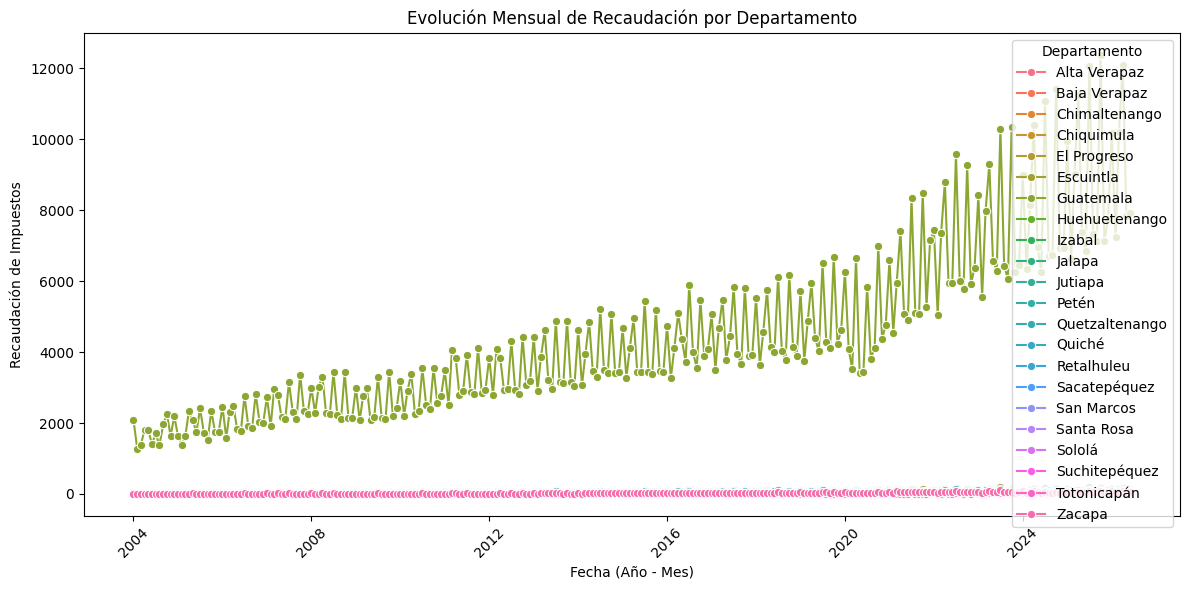

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df2_agrupado, 
    x='fecha', 
    y='MillonesQ', 
    hue='Departamento', 
    marker='o'
)

plt.title('Evolución Mensual de Recaudación por Departamento')
plt.xlabel('Fecha (Año - Mes)')
plt.ylabel('Recaudación de Impuestos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

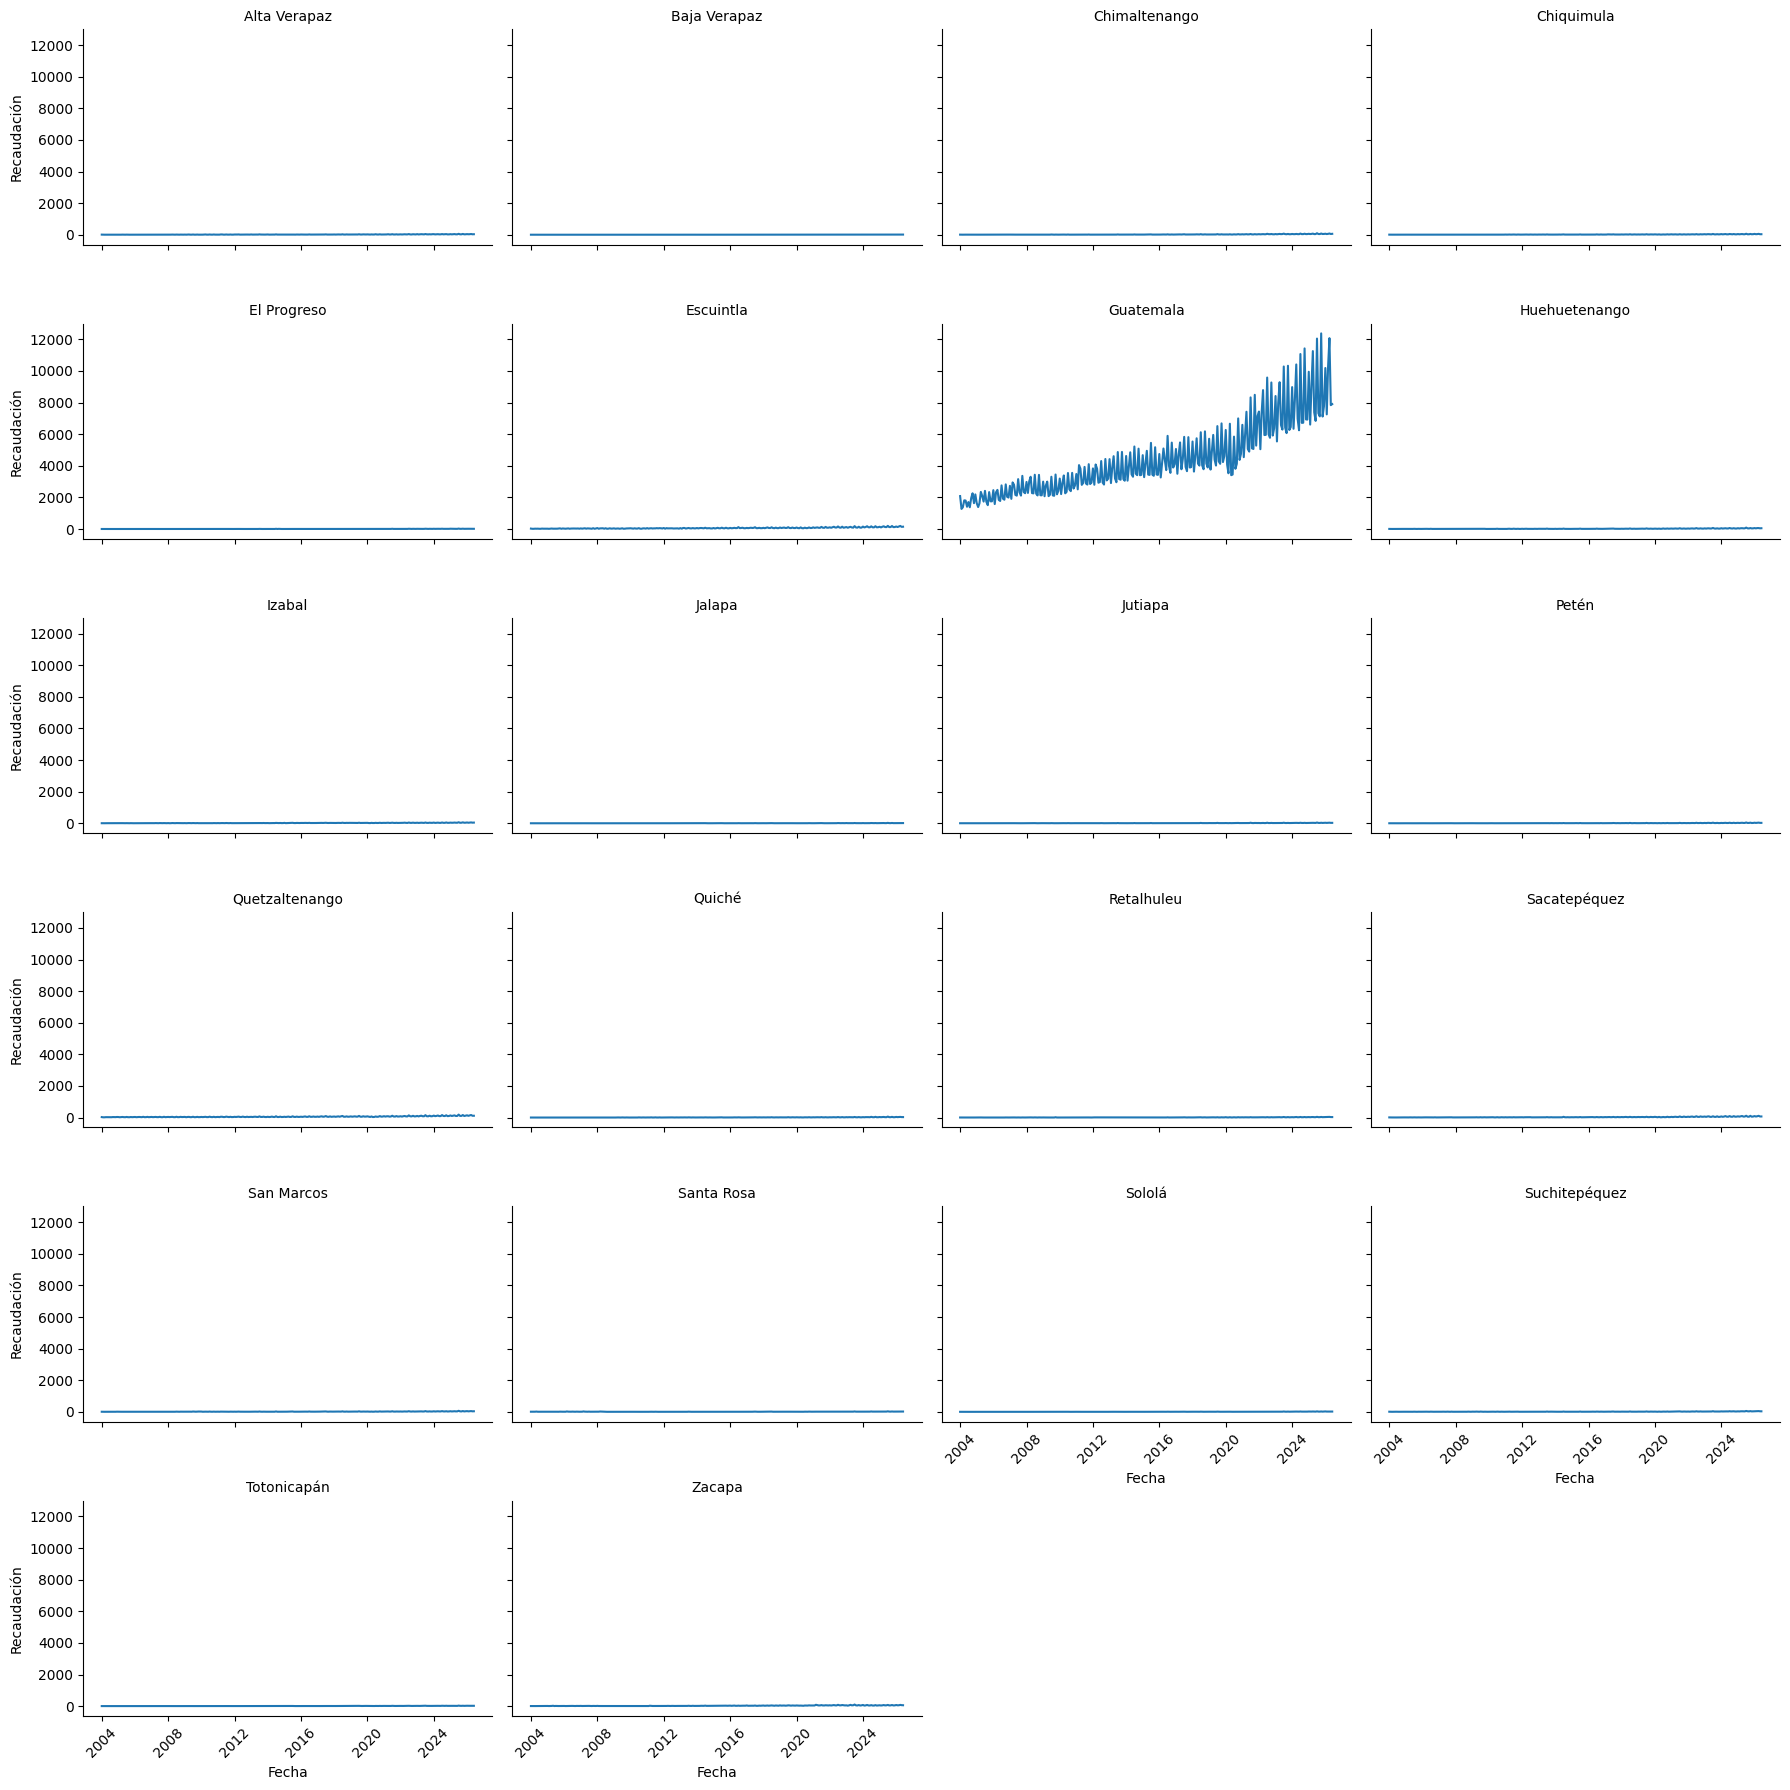

In [22]:
g = sns.relplot(
    data=df2_agrupado, 
    x='fecha', 
    y='MillonesQ', 
    col='Departamento', 
    col_wrap=4,      # 4 gráficos por fila
    kind='line', 
    height=3, 
    aspect=1.5
)

g.set_titles("{col_name}")
g.set_axis_labels("Fecha", "Recaudación")
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [4]:
# Modelo predictivo
#A partir de acá con los archivos de impuestos del 2021 al 2026 
#se tratará de entrenar un modelo y predecir los impuestos del último trimestre del 2026 y todo el 2027.

In [18]:
import pandas as pd
import glob

# 1. Buscar todos los archivos 'TR202*.xlsx' que correspnode a la ejecución de recaudación
archivos = sorted(glob.glob('TR202*.xlsx'))
lista_dfs = []

# quiero usar el contador para hacer un ciclo y luego generar año en el nombre de la hora de excel
for i, archivo in enumerate(archivos, start=1):
    anio = 2020+i
    nombre_hoja = f"Recaudación {anio} Depto. y AE"
    if i<5: 
        headerEx=4 
    else: 
        headerEx=3
    df_temp = pd.read_excel(
        archivo,
        sheet_name=nombre_hoja,
        header=headerEx,
        usecols="B:X",
        dtype={"Código Actividad": str}
    )
    #Hay que agregar la columna año para poder luego diferenciar la información de cada año
    df_temp ["Año"] = anio
    lista_dfs.append(df_temp)

# Unir todos los DataFrames en uno solo al terminar el ciclo
df = pd.concat(lista_dfs, ignore_index=True)

# 3. Verificar que estén los 6 años completos
print("Años cargados:", df['Año'].unique())
print("Total de filas:", len(df))

Años cargados: [2021 2022 2023 2024 2025 2026]
Total de filas: 620575


In [28]:
# Ver columnas y tipos de datos
print(df.info())

# Revisar registros faltantes
print(df.isnull().sum())

# Meses disponibles
print("Meses:", sorted(df["Mes"].dropna().unique()))

# Departamentos disponibles
print("Departamentos:", df["Departamento"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 620575 entries, 0 to 620574
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Mes               620575 non-null  int64         
 1   Código Actividad  620575 non-null  object        
 2   Nombre Actividad  620575 non-null  object        
 3   Nombre Sección    620575 non-null  object        
 4   Departamento      620575 non-null  object        
 5   IVA Importación   620575 non-null  float64       
 6   DAI               620575 non-null  float64       
 7   ISR               620575 non-null  float64       
 8   ISO               620575 non-null  float64       
 9   IEMA              620575 non-null  float64       
 10  IETAAP            620575 non-null  float64       
 11  ISET              620575 non-null  float64       
 12  PATRIMONIO        620575 non-null  float64       
 13  IVA Doméstico     620575 non-null  float64       
 14  BEBI

In [20]:
# Voy a convertir el año y mes a una fecha en particular, es decir al día 1 de cada mes

In [29]:
# 1. Crear una columna de fecha real combinando año y mes
df['fecha'] = pd.to_datetime(
    df['Año'].astype(str) + '-' + df['Mes'].astype(str) + '-01'
)

# 2. Agrupar por fecha y departamento sumando la recaudación
df_agrupado = df.groupby(['fecha', 'Departamento'])['TOTAL'].sum().reset_index()

display(df_agrupado.head(10))
print("Dimensiones:", df_agrupado.shape)

,fecha,Departamento,TOTAL
0,2021-01-01,Alta Verapaz,2.216350e+07
1,2021-01-01,Baja Verapaz,5.348223e+06
2,2021-01-01,Chimaltenango,2.977426e+07
3,2021-01-01,Chiquimula,2.773923e+07
4,2021-01-01,El Progreso,8.890020e+06
5,2021-01-01,Escuintla,1.044254e+08
6,2021-01-01,Guatemala,6.593104e+09
7,2021-01-01,Huehuetenango,3.007142e+07
8,2021-01-01,Izabal,2.773409e+07
9,2021-01-01,Jalapa,8.042786e+06


Dimensiones: (1496, 3)


In [30]:
recaudacion_mensual = (
    df.groupby(pd.Grouper(key="fecha", freq="MS"))["TOTAL"]
    .sum()
    .reset_index()
)
# Ordenar de acuerdo a la fecha
recaudacion_mensual = recaudacion_mensual.sort_values("fecha")
print(recaudacion_mensual.head())

       fecha         TOTAL
0 2021-01-01  7.183484e+09
1 2021-02-01  4.966775e+09
2 2021-03-01  6.508337e+09
3 2021-04-01  8.052547e+09
4 2021-05-01  5.507293e+09


In [31]:
#Mostrar datos unificados para tratar de ver un comportamiento

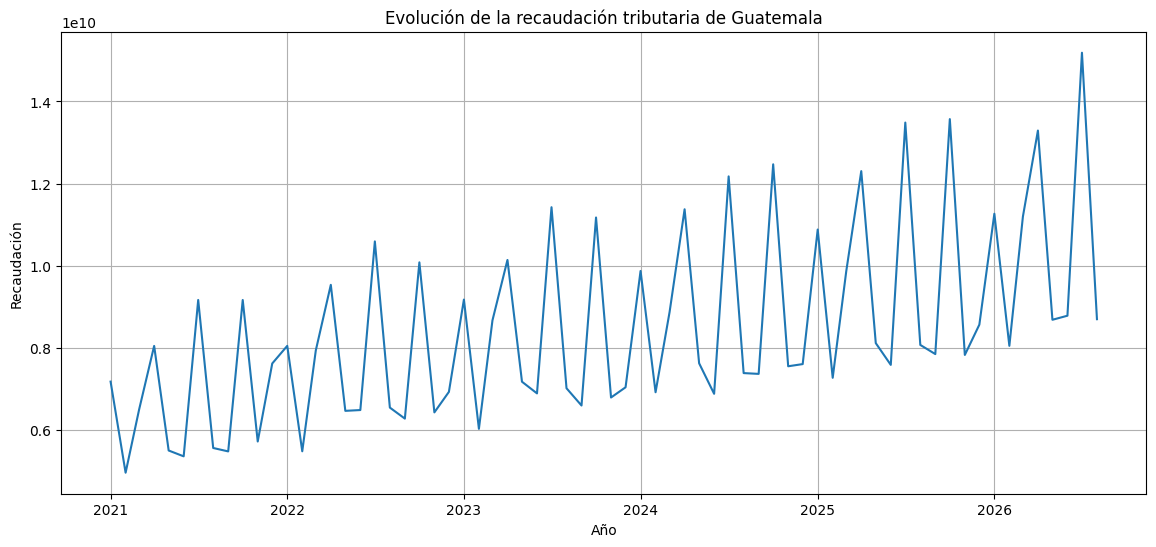

In [32]:
#Tratando de presentar el comportamiento de los 6 archivos unidos en un gráfico de
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    recaudacion_mensual["fecha"],
    recaudacion_mensual["TOTAL"]
)

plt.title("Evolución de la recaudación tributaria de Guatemala")
plt.xlabel("Año")
plt.ylabel("Recaudación")
plt.grid(True)

plt.show()